# 03 – Late Delivery EDA
**Stage 2 – TASK 02 (EDA01–EDA08)** · Owner: Phong

**Input:** `data/processed/research_data.csv` (1 row = 1 order, 99,441 rows, 34 columns).
**Output:** figures → `outputs/figures/`, tables → `outputs/tables/`, written findings → `docs/eda_findings_eng.md`.
(TASK 03 – Class Imbalance Analysis is a separate notebook: `03b_class_imbalance_analysis.ipynb`.)

**Ground rules**
- Only orders with a valid `is_late` label (0/1) enter the Late Delivery Rate. Cancelled / undelivered / missing-date orders are **not** treated as "not late".
- Every rate table reports `valid_orders`, `late_orders`, `late_rate`; groups with `valid_orders < 100` are flagged as unstable.
- Missing values are **never** replaced by 0; they are reported separately.
- EDA is descriptive only: **no causal claims** and no statistical-significance claims (tests belong to the Inference stage).
- Monthly Wilson 95% CIs belong to TASK 06 and are not computed here.

## 0. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# ---------- CONFIG ----------
def find_project_root(start=None):
    # Walk up from the current directory until data/processed/research_data.csv is found
    # (works when run from the repo root or from notebooks/).
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "data" / "processed" / "research_data.csv").exists():
            return p
    raise FileNotFoundError("Could not find data/processed/research_data.csv from " + str(start))

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "research_data.csv"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
EXPECTED_SHAPE = (99441, 34)   # official research_data.csv in the repo
SAVE_OUTPUTS = True            # False = display only, do not write files
MIN_N = 100                    # groups with valid_orders < MIN_N are flagged "low n"
VERY_LOW_N = 30                # groups with valid_orders < 30 are flagged "very low n"
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
C_LATE, C_OK, C_FLAG = "#d62728", "#4c72b0", "#bdbdbd"
# ----------------------------

if SAVE_OUTPUTS:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    if SAVE_OUTPUTS:
        fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def save_table(df_, name):
    if SAVE_OUTPUTS:
        df_.to_csv(TABLE_DIR / f"{name}.csv", index=True)

## 1. Load data & define the analysis sample

In [2]:
print("PROJECT_ROOT:", PROJECT_ROOT)
print("Reading data from:", DATA_PATH)

date_cols = [
    "order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
    "order_delivered_customer_date", "order_estimated_delivery_date",
]
df = pd.read_csv(DATA_PATH, parse_dates=date_cols)

print("Shape:", df.shape)
if df.shape != EXPECTED_SHAPE:
    print(f"WARNING: shape differs from the official file {EXPECTED_SHAPE}. Check the research_data.csv version before using these results.")
assert df["order_id"].is_unique, "Duplicate order_id -> data is no longer at order level"
df.dtypes

PROJECT_ROOT: C:\Users\ADMIN\OneDrive\Desktop\Group5_STAT3013.R11
Reading data from: C:\Users\ADMIN\OneDrive\Desktop\Group5_STAT3013.R11\data\processed\research_data.csv
Shape: (99441, 34)


order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
flag_approval_before_purchase            object
flag_carrier_before_purchase             object
flag_delivery_before_carrier             object
flag_delivery_before_purchase            object
flag_delivered_missing_date                bool
is_late                                 float64
purchase_weekday                         object
purchase_month                           object
promised_days                           float64
customer_state                           object
items_value                             float64
freight_value                           float64
item_count                              

In [3]:
# ---- Sample selection table ----
n_total = len(df)
n_delivered = (df["order_status"] == "delivered").sum()
mask_valid = df["is_late"].notna()
n_valid = mask_valid.sum()
n_late = int((df["is_late"] == 1).sum())
n_not_late = int((df["is_late"] == 0).sum())

assert set(df.loc[mask_valid, "is_late"].unique()) <= {0, 1}, "is_late has values outside {0, 1}"

sample_table = pd.DataFrame({
    "Item": [
        "Total orders (order level)",
        "Orders with order_status = delivered",
        "Orders with a valid is_late label (analysis sample)",
        "   - is_late = 1 (Late)",
        "   - is_late = 0 (Not Late)",
        "Orders without a label (excluded from rate calculations)",
        "   - of which: not delivered",
        "   - of which: delivered but missing/invalid dates",
    ],
    "Orders": [
        n_total, n_delivered, n_valid, n_late, n_not_late, n_total - n_valid,
        int((df["order_status"] != "delivered").sum()),
        int(((df["order_status"] == "delivered") & ~mask_valid).sum()),
    ],
})
sample_table["% of all orders"] = (sample_table["Orders"] / n_total * 100).round(2)
save_table(sample_table.set_index("Item"), "eda00_sample_selection")
sample_table

,Item,Orders,% of all orders
0,Total orders (order level),99441,100.00
1,Orders with order_status = delivered,96478,97.02
2,Orders with a valid is_late label (analysis sa...,96470,97.01
3,- is_late = 1 (Late),6534,6.57
4,- is_late = 0 (Not Late),89936,90.44
5,Orders without a label (excluded from rate cal...,2971,2.99
6,- of which: not delivered,2963,2.98
7,- of which: delivered but missing/invalid d...,8,0.01


In [4]:
# df_valid: the sample used for every late-rate computation
df_valid = df.loc[mask_valid].copy()
df_valid["is_late"] = df_valid["is_late"].astype(int)
OVERALL_RATE = df_valid["is_late"].mean()
print(f"Valid orders: {len(df_valid):,} | Late: {df_valid['is_late'].sum():,} | Overall late rate: {OVERALL_RATE:.4%}")

# Missing values per column within the valid sample (NOT filled with 0)
cols_check = ["customer_state", "purchase_weekday", "purchase_month", "distance_km_mean",
              "freight_value", "promised_days", "items_value", "seller_count", "has_interstate_seller"]
missing_valid = pd.DataFrame({
    "missing": df_valid[cols_check].isna().sum(),
    "missing_%": (df_valid[cols_check].isna().mean() * 100).round(2),
})
missing_valid

Valid orders: 96,470 | Late: 6,534 | Overall late rate: 6.7731%


,missing,missing_%
customer_state,0,0.00
purchase_weekday,0,0.00
purchase_month,0,0.00
distance_km_mean,480,0.50
freight_value,0,0.00
promised_days,18,0.02
items_value,0,0.00
seller_count,0,0.00
has_interstate_seller,0,0.00


### 1.1 Time-based variables used for EDA06–EDA08
The official 34-column `research_data.csv` already contains `estimated_window_days` and `delivery_delay_days` (created in TASK 01). This notebook **uses the existing columns** and **recomputes them independently (calendar days) for reconciliation only** – it never overwrites them without a check:
- `estimated_window_days` = estimated delivery date − purchase date
- `delivery_delay_days` = actual delivery date − estimated delivery date (negative = early, 0 = on the promised day, positive = late)

If an older 28-column file is used (without these columns), the recomputed version is used and a warning is printed. Any mismatch is only **reported**, never silently fixed.
**Variable classification:** `delivery_delay_days` is for EDA only and must not be used as a model input. `estimated_window_days` may be used for early prediction only if the estimated date is known at prediction time – to be confirmed in TASK 04.

In [5]:
purchase_d = df_valid["order_purchase_timestamp"].dt.normalize()
estimated_d = df_valid["order_estimated_delivery_date"].dt.normalize()
delivered_d = df_valid["order_delivered_customer_date"].dt.normalize()

recalc = {
    "estimated_window_days": (estimated_d - purchase_d).dt.days,
    "delivery_delay_days": (delivered_d - estimated_d).dt.days,
}
recon_rows = []
for col, calc in recalc.items():
    if col in df_valid.columns:
        given = df_valid[col]
        both = given.notna() & calc.notna()
        mism = int((given[both] != calc[both]).sum()) + int((given.isna() != calc.isna()).sum())
        recon_rows.append({"column": col, "source used": "existing CSV column", "rows differing from recomputation": mism})
    else:
        df_valid[col] = calc
        recon_rows.append({"column": col, "source used": "recomputed (column missing in CSV)", "rows differing from recomputation": np.nan})
        print(f"WARNING: CSV has no {col}; using the recomputed version. Run on the official 34-column file.")
recon_df = pd.DataFrame(recon_rows).set_index("column")
save_table(recon_df, "eda00_temporal_feature_reconciliation")
display(recon_df)   # if any rows differ: report to the TASK 01 owner, do not fix silently

# Consistency check: is_late == 1  <=>  delivery_delay_days > 0 (using the columns in use)
consistent = ((df_valid["delivery_delay_days"] > 0).astype(int) == df_valid["is_late"])
print(f"is_late agrees with delivery_delay_days > 0: {consistent.mean():.4%} ({(~consistent).sum()} rows differ)")
assert consistent.all(), "is_late disagrees with delivery_delay_days -> report to the label owner (do not fix silently)"

print("Missing estimated_window_days:", df_valid["estimated_window_days"].isna().sum())
print("Missing delivery_delay_days  :", df_valid["delivery_delay_days"].isna().sum())
print("estimated_window_days < 0:", (df_valid["estimated_window_days"] < 0).sum())
df_valid[["estimated_window_days", "delivery_delay_days"]].describe().T

,source used,rows differing from recomputation
column,,
estimated_window_days,existing CSV column,0
delivery_delay_days,existing CSV column,0


is_late agrees with delivery_delay_days > 0: 100.0000% (0 rows differ)
Missing estimated_window_days: 0
Missing delivery_delay_days  : 0
estimated_window_days < 0: 0


,count,mean,std,min,25%,50%,75%,max
estimated_window_days,96470.0,24.372738,8.758428,3.0,19.0,24.0,29.0,156.0
delivery_delay_days,96470.0,-11.875889,10.182105,-147.0,-17.0,-12.0,-7.0,188.0


## 2. Helper functions for group-wise rates

In [6]:
def late_rate_table(data, group_col, order=None, sort_by=None, ascending=True, dropna=False):
    # Table: valid_orders, late_orders, late_rate, reliability. Denominator = orders with a valid label.
    g = data.groupby(group_col, dropna=dropna, observed=True)["is_late"]
    t = g.agg(valid_orders="size", late_orders="sum").astype({"valid_orders": int, "late_orders": int})
    t["late_rate"] = t["late_orders"] / t["valid_orders"]
    t["share_of_valid_%"] = (t["valid_orders"] / len(data) * 100).round(2)
    t["reliability"] = np.where(t["valid_orders"] < VERY_LOW_N, "VERY LOW n (<30) - do not interpret",
                        np.where(t["valid_orders"] < MIN_N, "LOW n (<100) - unstable", "ok"))
    if order is not None:
        t = t.reindex(order)
    if sort_by is not None:
        t = t.sort_values(sort_by, ascending=ascending)
    return t

def fmt_pct(t):
    out = t.copy()
    out["late_rate"] = (out["late_rate"] * 100).round(2).astype(str) + "%"
    return out

## EDA01 – Late / Not Late distribution (Count Plot)

In [7]:
eda01 = (df_valid["is_late"].map({0: "Not Late (0)", 1: "Late (1)"})
         .value_counts().reindex(["Not Late (0)", "Late (1)"]).to_frame("valid_orders"))
eda01["%"] = (eda01["valid_orders"] / eda01["valid_orders"].sum() * 100).round(2)
save_table(eda01, "eda01_late_distribution")
eda01

,valid_orders,%
is_late,,
Not Late (0),89936,93.23
Late (1),6534,6.77


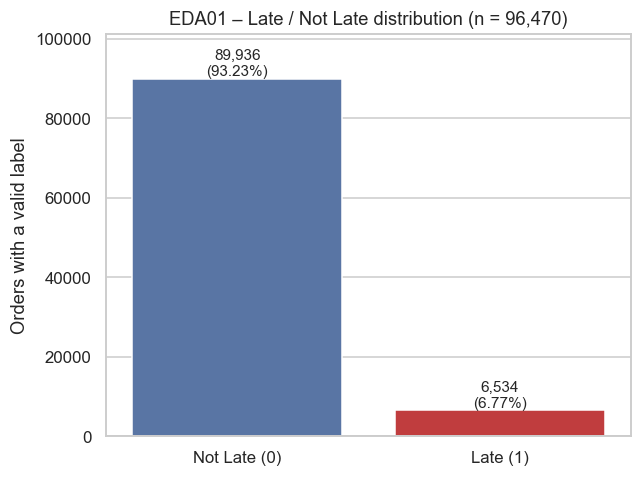

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_df = df_valid.assign(label=df_valid["is_late"].map({0: "Not Late (0)", 1: "Late (1)"}))
sns.countplot(data=plot_df, x="label", order=["Not Late (0)", "Late (1)"],
              palette=[C_OK, C_LATE], hue="label", legend=False, ax=ax)
total = len(plot_df)
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(f"{int(h):,}\n({h/total:.2%})", (p.get_x() + p.get_width()/2, h),
                    ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, total * 1.05)
ax.set_xlabel("")
ax.set_ylabel("Orders with a valid label")
ax.set_title(f"EDA01 – Late / Not Late distribution (n = {total:,})")
plt.tight_layout(); save_fig(fig, "eda01_late_distribution"); plt.show()

**EDA01 findings:** Of the 96,470 orders with a valid label, 6,534 were delivered late (**6.77%**) and 89,936 were not (**93.23%**). Late is clearly the minority class (analysed further in Part B – Class Imbalance).

## EDA02 – Late Delivery Rate by purchase weekday (Bar Chart)

In [9]:
eda02 = late_rate_table(df_valid, "purchase_weekday", order=WEEKDAY_ORDER)
save_table(eda02, "eda02_late_rate_by_weekday")
fmt_pct(eda02)

,valid_orders,late_orders,late_rate,share_of_valid_%,reliability
purchase_weekday,,,,,
Monday,15701,1168,7.44%,16.28,ok
Tuesday,15502,1093,7.05%,16.07,ok
Wednesday,15074,990,6.57%,15.63,ok
Thursday,14322,903,6.3%,14.85,ok
Friday,13684,960,7.02%,14.18,ok
Saturday,10555,696,6.59%,10.94,ok
Sunday,11632,724,6.22%,12.06,ok


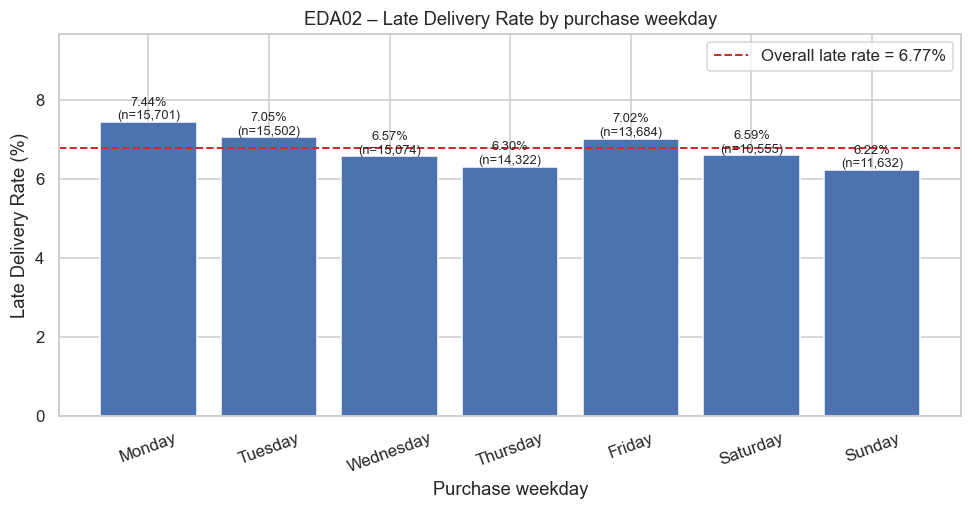

In [10]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [C_FLAG if n < MIN_N else C_OK for n in eda02["valid_orders"]]
bars = ax.bar(eda02.index, eda02["late_rate"] * 100, color=colors)
ax.axhline(OVERALL_RATE * 100, color=C_LATE, ls="--", lw=1.3, label=f"Overall late rate = {OVERALL_RATE:.2%}")
for b, (_, r) in zip(bars, eda02.iterrows()):
    ax.annotate(f"{r['late_rate']:.2%}\n(n={int(r['valid_orders']):,})", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, eda02["late_rate"].max() * 100 * 1.3)
ax.set_ylabel("Late Delivery Rate (%)"); ax.set_xlabel("Purchase weekday")
ax.set_title("EDA02 – Late Delivery Rate by purchase weekday")
ax.legend(loc="upper right")
plt.xticks(rotation=20); plt.tight_layout(); save_fig(fig, "eda02_late_rate_by_weekday"); plt.show()

**EDA02 findings:** The late rate varies narrowly by weekday, from **6.22% (Sunday)** to **7.44% (Monday)** around the overall 6.77%. Monday, Tuesday and Friday are slightly above the overall rate; Sunday and Thursday are lowest. The spread is small (~1.2 percentage points). Each group is large (>10,000 orders), but uncertainty is not quantified in this task → descriptive observation only, no statistical-significance claim.

## EDA03 – Late Delivery Rate by month (Line Chart)

In [11]:
eda03 = late_rate_table(df_valid, "purchase_month").sort_index()
plot03 = eda03[eda03["valid_orders"] >= MIN_N]                       # months that are plotted
plot03_1718 = plot03[plot03.index >= "2017-01"]                        # 2017–2018 only
save_table(eda03, "eda03_late_rate_by_month")
fmt_pct(eda03)

,valid_orders,late_orders,late_rate,share_of_valid_%,reliability
purchase_month,,,,,
2016-09,1,1,100.0%,0.00,VERY LOW n (<30) - do not interpret
2016-10,265,2,0.75%,0.27,ok
2016-12,1,0,0.0%,0.00,VERY LOW n (<30) - do not interpret
2017-01,750,22,2.93%,0.78,ok
2017-02,1653,49,2.96%,1.71,ok
2017-03,2546,116,4.56%,2.64,ok
2017-04,2303,151,6.56%,2.39,ok
2017-05,3545,106,2.99%,3.67,ok
2017-06,3135,95,3.03%,3.25,ok


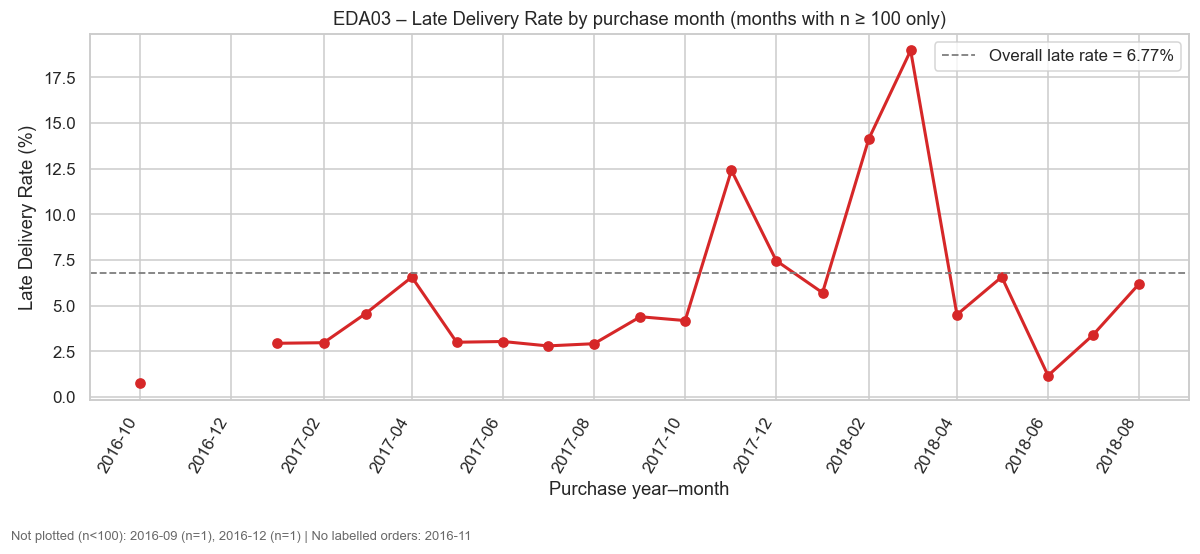

In [12]:
# Datetime axis: keep gaps for months with no orders or too few orders (n < MIN_N) – the line is not drawn across gaps
eda03_dt = eda03.copy()
eda03_dt.index = pd.PeriodIndex(eda03_dt.index, freq="M").to_timestamp()
full_idx = pd.date_range(eda03_dt.index.min(), eda03_dt.index.max(), freq="MS")
rate_plot = (eda03_dt["late_rate"].where(eda03_dt["valid_orders"] >= MIN_N) * 100).reindex(full_idx)
excluded = eda03[eda03["valid_orders"] < MIN_N]
no_orders = [d.strftime("%Y-%m") for d in full_idx if d not in eda03_dt.index]

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(rate_plot.index, rate_plot.values, marker="o", color=C_LATE, lw=2)   # NaN => broken line
ax.axhline(OVERALL_RATE * 100, color="grey", ls="--", lw=1.2, label=f"Overall late rate = {OVERALL_RATE:.2%}")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_ylabel("Late Delivery Rate (%)"); ax.set_xlabel("Purchase year–month")
ax.set_title("EDA03 – Late Delivery Rate by purchase month (months with n ≥ 100 only)")
plt.xticks(rotation=60, ha="right")
notes = []
if len(excluded):
    notes.append("Not plotted (n<100): " + ", ".join(f"{m} (n={int(r.valid_orders)})" for m, r in excluded.iterrows()))
if no_orders:
    notes.append("No labelled orders: " + ", ".join(no_orders))
if notes:
    fig.text(0.01, -0.04, " | ".join(notes), fontsize=8.5, color="dimgray")
ax.legend()
plt.tight_layout(); save_fig(fig, "eda03_late_rate_by_month"); plt.show()

**EDA03 findings:** The late rate fluctuates strongly by month. Among months with n ≥ 100 the lowest is **2016-10 (0.75%, n = 265)**; within 2017–2018 alone the lowest is **2018-06 (1.16%)**. Mid-2017 sits at ≈2.8–3.0% (2017-05 to 2017-08), jumps to **12.4% in 2017-11**, and peaks at **19.0% in 2018-03** (14.1% in 2018-02). Only 2016-09 (n = 1) and 2016-12 (n = 1) are dropped from the chart by the n ≥ 100 rule (2016-09 has 1 late order, so its "100%" is noise); 2016-11 has no labelled orders and is left as a gap on the time axis; 2016-10 is plotted but stands alone (not connected to 2017-01). Descriptive only – no causal or seasonality claim. Wilson CIs and monthly data completeness belong to TASK 06.

## EDA04 – Late Delivery Rate by customer state (Bar Chart)

In [13]:
eda04 = late_rate_table(df_valid, "customer_state", sort_by="late_rate", ascending=False)
save_table(eda04, "eda04_late_rate_by_state")
fmt_pct(eda04)

,valid_orders,late_orders,late_rate,share_of_valid_%,reliability
customer_state,,,,,
AL,397,85,21.41%,0.41,ok
MA,717,125,17.43%,0.74,ok
SE,335,51,15.22%,0.35,ok
PI,476,66,13.87%,0.49,ok
CE,1279,176,13.76%,1.33,ok
RR,41,5,12.2%,0.04,LOW n (<100) - unstable
BA,3256,396,12.16%,3.38,ok
RJ,12350,1495,12.11%,12.80,ok
PA,946,106,11.21%,0.98,ok


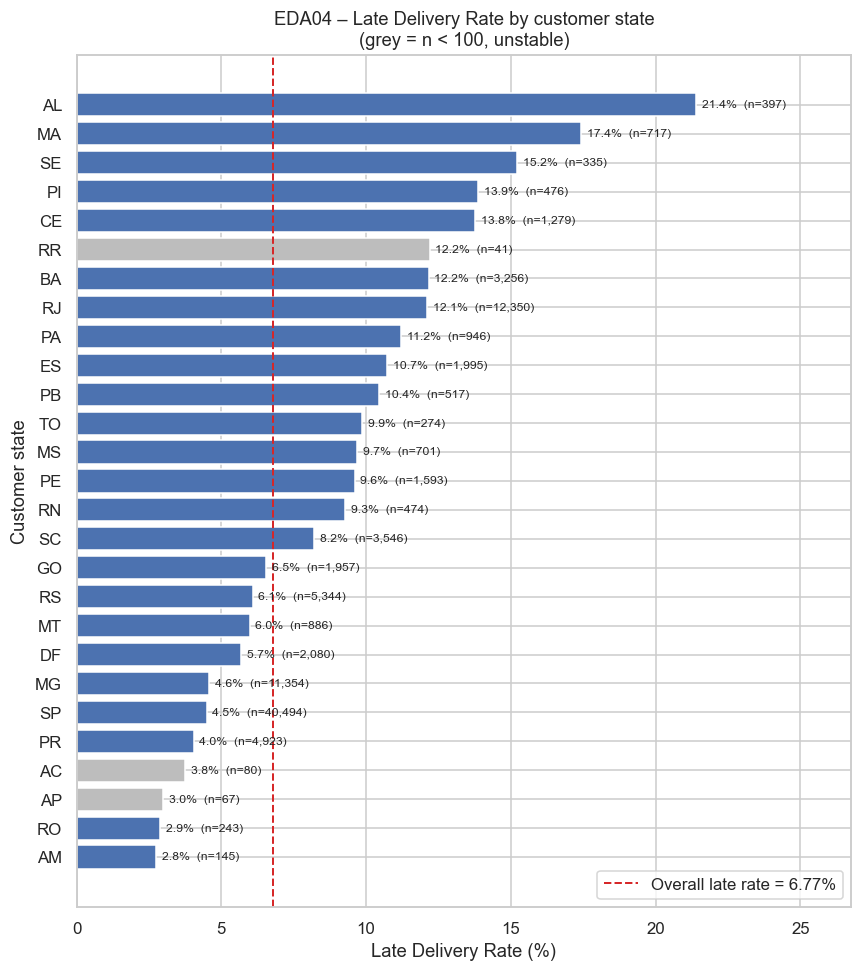

In [14]:
fig, ax = plt.subplots(figsize=(8, 9))
plot04 = eda04.sort_values("late_rate", ascending=True)
colors = [C_FLAG if n < MIN_N else C_OK for n in plot04["valid_orders"]]
ax.barh(plot04.index, plot04["late_rate"] * 100, color=colors)
ax.axvline(OVERALL_RATE * 100, color=C_LATE, ls="--", lw=1.3, label=f"Overall late rate = {OVERALL_RATE:.2%}")
for y, (_, r) in enumerate(plot04.iterrows()):
    ax.text(r["late_rate"] * 100 + 0.2, y, f"{r['late_rate']:.1%}  (n={int(r['valid_orders']):,})", va="center", fontsize=8)
ax.set_xlim(0, plot04["late_rate"].max() * 100 * 1.25)
ax.set_xlabel("Late Delivery Rate (%)"); ax.set_ylabel("Customer state")
ax.set_title("EDA04 – Late Delivery Rate by customer state\n(grey = n < 100, unstable)")
ax.legend(loc="lower right")
plt.tight_layout(); save_fig(fig, "eda04_late_rate_by_state"); plt.show()

**EDA04 findings:** There are 27 states, with very large differences: highest **AL 21.4%**, MA 17.4%, SE 15.2%, PI 13.9%, CE 13.8%; some states have low rates (PR 4.0%, SP 4.5%, MG 4.6% among large states; AM 2.8% and RO 2.9% are lower still but have small samples). **RJ (12.1%, n = 12,350) and BA (12.2%)** are almost three times SP/PR/MG. The north-eastern states (AL, MA, SE, PI, CE, BA) generally have high late rates. **AP (n = 67), RR (n = 41) and AC (n = 80)** have n < 100, so their rates are unstable (AM n = 145 and RO n = 243 are also small – interpret with care). SP is ~42% of the sample, so the overall rate is pulled toward SP's level.

## EDA05 – Late Delivery Rate by distance group (Bar Chart)
**Grouping:** `distance_km_mean` (Haversine, straight-line) is binned with fixed thresholds, half-open intervals `[a, b)`:
0–100, 100–300, 300–600, 600–1,000, 1,000–2,000, ≥2,000 km.
**Missing:** orders without a distance (no items, or missing coordinates) are **not** assigned to any group; they appear as a separate `Missing` row in the table and are excluded from the chart.

In [15]:
DIST_BINS = [0, 100, 300, 600, 1000, 2000, np.inf]
DIST_LABELS = ["0–100 km", "100–300 km", "300–600 km", "600–1,000 km", "1,000–2,000 km", "≥ 2,000 km"]
df_valid["distance_group"] = pd.cut(df_valid["distance_km_mean"], bins=DIST_BINS, labels=DIST_LABELS, right=False)

eda05 = late_rate_table(df_valid[df_valid["distance_group"].notna()], "distance_group", order=DIST_LABELS)
miss = df_valid[df_valid["distance_group"].isna()]
eda05_full = eda05.copy()
eda05_full.loc["Missing (no distance)"] = [
    len(miss), int(miss["is_late"].sum()), miss["is_late"].mean(), round(len(miss) / len(df_valid) * 100, 2),
    "ok" if len(miss) >= MIN_N else "LOW n",
]
# share_of_valid_% is computed over ALL labelled orders for both the binned groups and the Missing row
eda05_full["share_of_valid_%"] = (eda05_full["valid_orders"] / len(df_valid) * 100).round(2)
assert abs(eda05_full["share_of_valid_%"].sum() - 100) < 0.05
save_table(eda05_full, "eda05_late_rate_by_distance_group")
fmt_pct(eda05_full)

,valid_orders,late_orders,late_rate,share_of_valid_%,reliability
distance_group,,,,,
0–100 km,17815,796,4.47%,18.47,ok
100–300 km,13440,693,5.16%,13.93,ok
300–600 km,31485,2128,6.76%,32.64,ok
"600–1,000 km",17910,1272,7.1%,18.57,ok
"1,000–2,000 km",9727,924,9.5%,10.08,ok
"≥ 2,000 km",5613,676,12.04%,5.82,ok
Missing (no distance),480,45,9.38%,0.50,ok


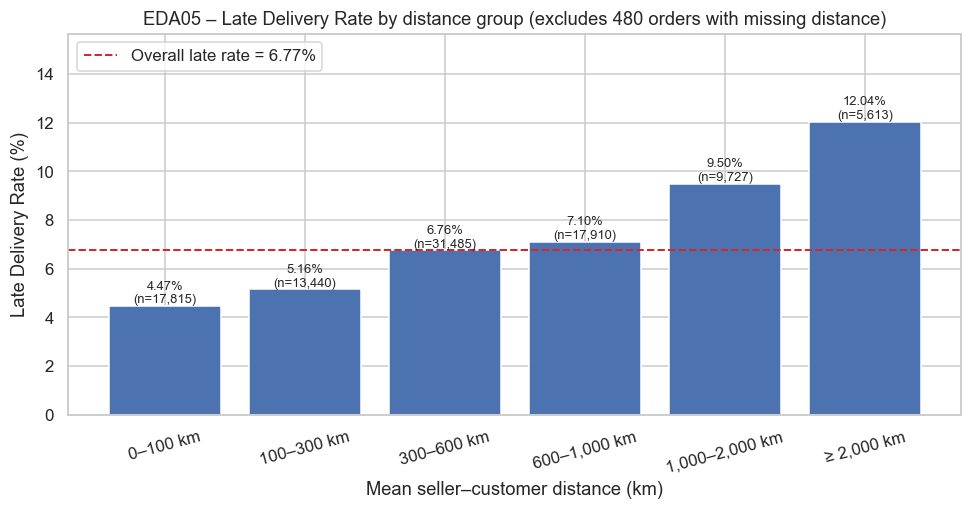

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.8))
colors = [C_FLAG if n < MIN_N else C_OK for n in eda05["valid_orders"]]
bars = ax.bar(eda05.index.astype(str), eda05["late_rate"] * 100, color=colors)
ax.axhline(OVERALL_RATE * 100, color=C_LATE, ls="--", lw=1.3, label=f"Overall late rate = {OVERALL_RATE:.2%}")
for b, (_, r) in zip(bars, eda05.iterrows()):
    ax.annotate(f"{r['late_rate']:.2%}\n(n={int(r['valid_orders']):,})", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, eda05["late_rate"].max() * 100 * 1.3)
ax.set_xlabel("Mean seller–customer distance (km)"); ax.set_ylabel("Late Delivery Rate (%)")
ax.set_title(f"EDA05 – Late Delivery Rate by distance group (excludes {len(miss):,} orders with missing distance)")
ax.legend(loc="upper left")
plt.xticks(rotation=15); plt.tight_layout(); save_fig(fig, "eda05_late_rate_by_distance_group"); plt.show()

**EDA05 findings:** The late rate **rises steadily with distance**: 4.47% (<100 km) → 5.16% → 6.76% → 7.10% → 9.50% → **12.04% (≥2,000 km)**, i.e. the farthest group is ~2.7× the nearest. Every group has n > 5,000. The 480 orders (0.50%) with missing distance have a late rate of 9.38% and are reported separately. This is an observed association; distance may co-vary with state, estimated window, etc. (confounding), so no causal conclusion is drawn.

## EDA06 – Freight value: Late vs Not Late (Boxplot)

In [17]:
LABEL_MAP = {0: "Not Late", 1: "Late"}
df_valid["late_label"] = df_valid["is_late"].map(LABEL_MAP)

def describe_by_late(data, col):
    g = data.groupby("late_label")[col]
    t = g.agg(n="count", missing=lambda s: s.isna().sum(), mean="mean", sd="std",
              min="min", q1=lambda s: s.quantile(.25), median="median",
              q3=lambda s: s.quantile(.75), p95=lambda s: s.quantile(.95), max="max")
    t["IQR"] = t["q3"] - t["q1"]
    return t.reindex(["Not Late", "Late"]).round(2)

eda06 = describe_by_late(df_valid, "freight_value")
save_table(eda06, "eda06_freight_by_late")
eda06

,n,missing,mean,sd,min,q1,median,q3,p95,max,IQR
late_label,,,,,,,,,,,
Not Late,89936,0,22.61,21.38,0.0,13.71,17.06,23.85,54.37,1794.96,10.14
Late,6534,0,25.25,23.72,0.0,15.10,18.23,26.90,60.40,711.33,11.80


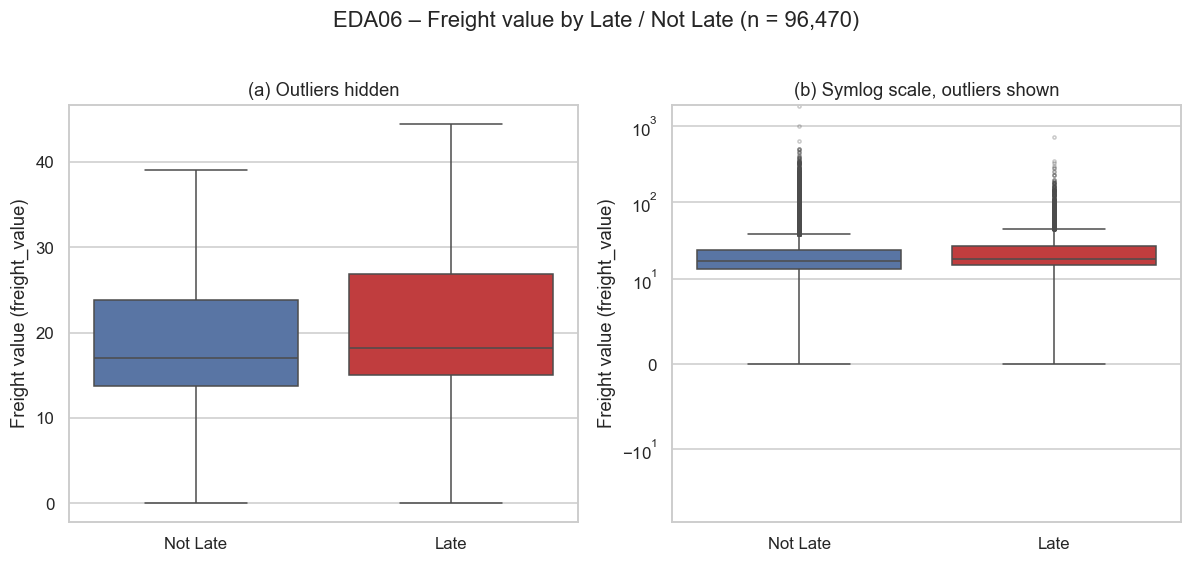

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
order = ["Not Late", "Late"]
pal = {"Not Late": C_OK, "Late": C_LATE}

# (a) Boxplot without outliers to show the body of the distribution
sns.boxplot(data=df_valid, x="late_label", y="freight_value", order=order, palette=pal, hue="late_label",
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("(a) Outliers hidden")

# (b) Boxplot on a symlog scale (freight can be 0)
sns.boxplot(data=df_valid, x="late_label", y="freight_value", order=order, palette=pal, hue="late_label",
            legend=False, ax=axes[1], flierprops=dict(markersize=2, alpha=.3))
axes[1].set_yscale("symlog", linthresh=10)
axes[1].set_title("(b) Symlog scale, outliers shown")

for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("Freight value (freight_value)")
fig.suptitle(f"EDA06 – Freight value by Late / Not Late (n = {df_valid['freight_value'].notna().sum():,})", y=1.02)
plt.tight_layout(); save_fig(fig, "eda06_freight_by_late"); plt.show()

**EDA06 findings:** No missing `freight_value` in the valid sample. Freight is strongly **right-skewed** (max 1,794.96 vs median ≈17). The Late group has slightly higher freight: median **18.23 vs 17.06**, Q3 26.90 vs 23.85, mean 25.25 vs 22.61; spread is similar (IQR 11.80 vs 10.14). A median gap of ≈1.17 currency units is small relative to the spread → the two distributions overlap heavily. Statistical significance is not assessed. (High freight often goes with heavy goods or long distances, so it may be confounded with distance.)

## EDA07 – Estimated window: Late vs Not Late (Boxplot)
`estimated_window_days` = estimated delivery date − purchase date (calendar days, see 1.1). It differs from `promised_days` in research_data.csv (counted from order approval; negative values were turned into missing); the tables below compare both.

In [19]:
eda07 = describe_by_late(df_valid, "estimated_window_days")
save_table(eda07, "eda07_estimated_window_by_late")
display(eda07)

eda07_promised = describe_by_late(df_valid, "promised_days")   # for reference; missing = missing approval date + negative values turned into missing
save_table(eda07_promised, "eda07_promised_days_by_late")
display(eda07_promised)

,n,missing,mean,sd,min,q1,median,q3,p95,max,IQR
late_label,,,,,,,,,,,
Not Late,89936,0,24.45,8.83,3,19.0,24.0,29.0,39.0,156,10.0
Late,6534,0,23.29,7.57,3,20.0,23.0,28.0,35.0,70,8.0


,n,missing,mean,sd,min,q1,median,q3,p95,max,IQR
late_label,,,,,,,,,,,
Not Late,89920,16,23.94,8.84,0.0,18.0,23.0,29.0,39.0,154.0,11.0
Late,6532,2,22.69,7.64,1.0,19.0,23.0,27.0,35.0,69.0,8.0


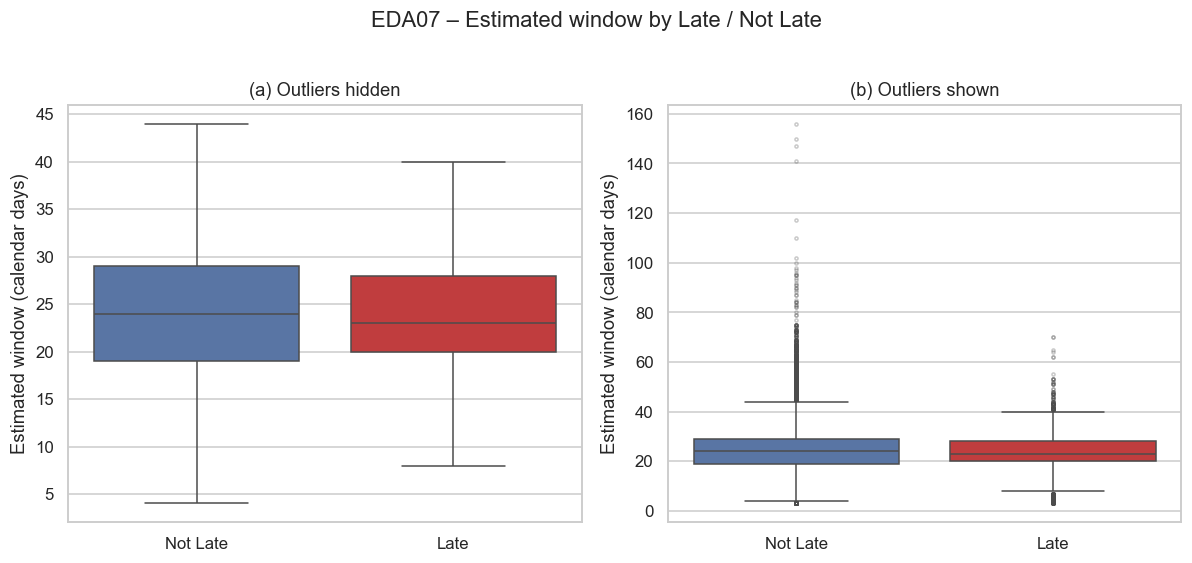

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
sns.boxplot(data=df_valid, x="late_label", y="estimated_window_days", order=order, palette=pal, hue="late_label",
            legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("(a) Outliers hidden")
sns.boxplot(data=df_valid, x="late_label", y="estimated_window_days", order=order, palette=pal, hue="late_label",
            legend=False, ax=axes[1], flierprops=dict(markersize=2, alpha=.3))
axes[1].set_title("(b) Outliers shown")
for ax in axes:
    ax.set_xlabel(""); ax.set_ylabel("Estimated window (calendar days)")
fig.suptitle("EDA07 – Estimated window by Late / Not Late", y=1.02)
plt.tight_layout(); save_fig(fig, "eda07_estimated_window_by_late"); plt.show()

In [21]:
# (Supplementary, descriptive) Late rate by estimated-window group – the relationship need not be monotonic
EW_BINS = [0, 15, 20, 25, 30, 40, np.inf]
EW_LABELS = ["≤15", "16–20", "21–25", "26–30", "31–40", ">40"]
df_valid["ew_group"] = pd.cut(df_valid["estimated_window_days"], bins=EW_BINS, labels=EW_LABELS, right=True)
eda07_extra = late_rate_table(df_valid, "ew_group", order=EW_LABELS)
assert {"valid_orders", "late_orders", "late_rate"} <= set(eda07_extra.columns)   # table must include late-order counts
save_table(eda07_extra, "eda07_late_rate_by_estimated_window_group")
fmt_pct(eda07_extra)

,valid_orders,late_orders,late_rate,share_of_valid_%,reliability
ew_group,,,,,
≤15,14039,829,5.9%,14.55,ok
16–20,16625,1183,7.12%,17.23,ok
21–25,26374,2142,8.12%,27.34,ok
26–30,19560,1395,7.13%,20.28,ok
31–40,16016,898,5.61%,16.60,ok
>40,3856,87,2.26%,4.00,ok


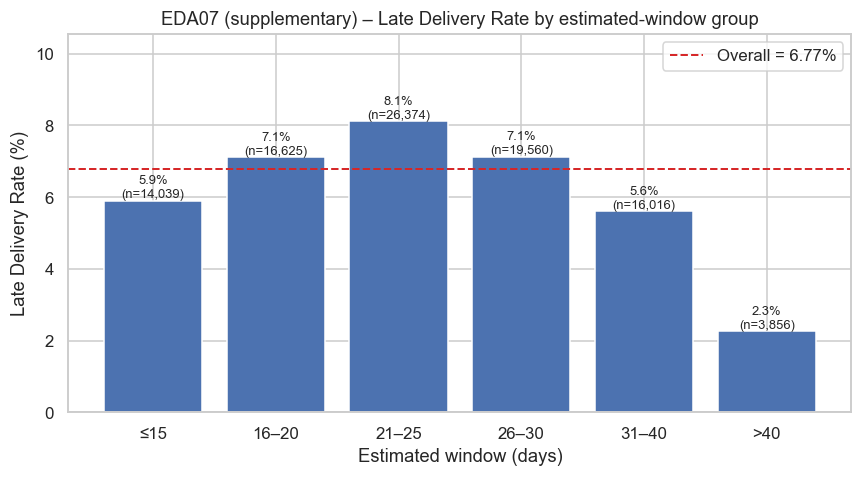

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(eda07_extra.index.astype(str), eda07_extra["late_rate"] * 100, color=C_OK)
ax.axhline(OVERALL_RATE * 100, color=C_LATE, ls="--", lw=1.3, label=f"Overall = {OVERALL_RATE:.2%}")
for b, (_, r) in zip(bars, eda07_extra.iterrows()):
    ax.annotate(f"{r['late_rate']:.1%}\n(n={int(r['valid_orders']):,})", (b.get_x() + b.get_width()/2, b.get_height()),
                ha="center", va="bottom", fontsize=8.5)
ax.set_ylim(0, eda07_extra["late_rate"].max() * 100 * 1.3)
ax.set_xlabel("Estimated window (days)"); ax.set_ylabel("Late Delivery Rate (%)")
ax.set_title("EDA07 (supplementary) – Late Delivery Rate by estimated-window group")
ax.legend(); plt.tight_layout(); save_fig(fig, "eda07_late_rate_by_estimated_window_group"); plt.show()

**EDA07 findings:** The estimated window of **Late orders is slightly shorter**: median **23 vs 24 days**, mean 23.29 vs 24.45; Q1–Q3 20–28 vs 19–29 (Late is less spread out: IQR 8 vs 10, max 70 vs 156). The two distributions overlap heavily. The supplementary table (with a `late_orders` column) shows a **non-monotonic** relationship: the late rate is highest in the 21–25-day group (8.1%) and lowest in the >40-day group (2.3%); one explanatory hypothesis (not a causal conclusion) is that a very long promised window leaves extra slack. `promised_days` gives similar results (median 23 vs 23); it is missing for 18 valid orders = 14 with a missing approval date + 4 with negative values (estimated date before approval date) that were turned into missing. Descriptive only; other variables are not controlled for.

## EDA08 – Distribution of delivery delay days (Histogram)
`delivery_delay_days` < 0: early; = 0: on the promised day; > 0: late (is_late = 1).

In [23]:
dd = df_valid["delivery_delay_days"]
eda08 = pd.DataFrame({
    "n": [dd.count()],
    "missing": [dd.isna().sum()],
    "mean": [dd.mean()], "sd": [dd.std()], "median": [dd.median()],
    "min": [dd.min()], "p1": [dd.quantile(.01)], "p5": [dd.quantile(.05)],
    "p95": [dd.quantile(.95)], "p99": [dd.quantile(.99)], "max": [dd.max()],
}).round(2)
eda08_split = pd.DataFrame({
    "valid_orders": [(dd < 0).sum(), (dd == 0).sum(), (dd > 0).sum()],
}, index=["Early (<0)", "On the promised day (=0)", "Late (>0)"])
eda08_split["%"] = (eda08_split["valid_orders"] / len(dd) * 100).round(2)

HIST_LO, HIST_HI = -60, 40
n_out_lo, n_out_hi = (dd < HIST_LO).sum(), (dd > HIST_HI).sum()
print(f"Outside the displayed range [{HIST_LO}, {HIST_HI}]: {n_out_lo} orders < {HIST_LO}, {n_out_hi} orders > {HIST_HI}")
save_table(eda08.T.rename(columns={0: "value"}), "eda08_delay_summary")
save_table(eda08_split, "eda08_delay_split")
display(eda08); display(eda08_split)
display(df_valid.groupby("late_label")["delivery_delay_days"].describe().round(2))

Outside the displayed range [-60, 40]: 34 orders < -60, 194 orders > 40


,n,missing,mean,sd,median,min,p1,p5,p95,p99,max
0,96470,0,-11.88,10.18,-12.0,-147.0,-36.0,-26.0,3.0,18.0,188.0


,valid_orders,%
Early (<0),88644,91.89
On the promised day (=0),1292,1.34
Late (>0),6534,6.77


,count,mean,std,min,25%,50%,75%,max
late_label,,,,,,,,
Late,6534.0,10.62,14.64,1.0,3.0,7.0,13.0,188.0
Not Late,89936.0,-13.51,7.50,-147.0,-17.0,-13.0,-8.0,0.0


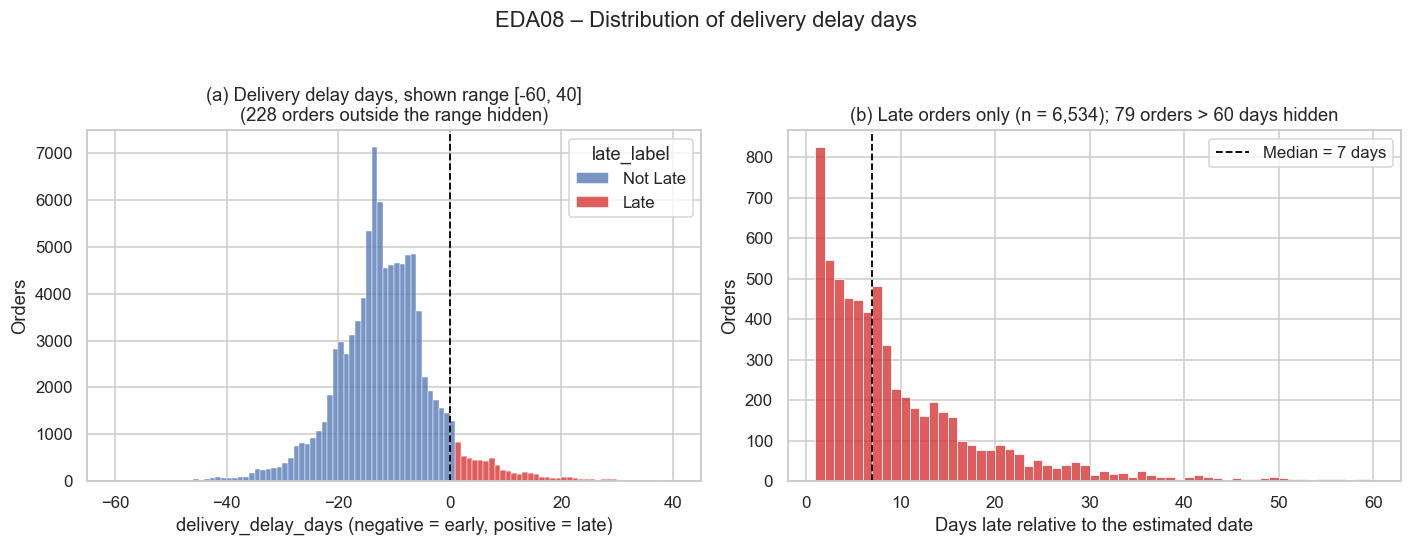

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) Whole distribution (axis clipped for readability)
sns.histplot(data=df_valid[df_valid["delivery_delay_days"].between(HIST_LO, HIST_HI)],
             x="delivery_delay_days", hue="late_label", hue_order=["Not Late", "Late"],
             palette=pal, binwidth=1, multiple="stack", ax=axes[0])
axes[0].axvline(0, color="black", ls="--", lw=1.2)
axes[0].set_title(f"(a) Delivery delay days, shown range [{HIST_LO}, {HIST_HI}]\n"
                  f"({n_out_lo + n_out_hi} orders outside the range hidden)")
axes[0].set_xlabel("delivery_delay_days (negative = early, positive = late)"); axes[0].set_ylabel("Orders")

# (b) Late orders only (zoom on the right tail)
late_only = df_valid.loc[df_valid["is_late"] == 1, "delivery_delay_days"]
sns.histplot(late_only[late_only <= 60], binwidth=1, color=C_LATE, ax=axes[1])
axes[1].axvline(late_only.median(), color="black", ls="--", lw=1.2, label=f"Median = {late_only.median():.0f} days")
axes[1].set_title(f"(b) Late orders only (n = {len(late_only):,}); {(late_only > 60).sum()} orders > 60 days hidden")
axes[1].set_xlabel("Days late relative to the estimated date"); axes[1].set_ylabel("Orders"); axes[1].legend()

fig.suptitle("EDA08 – Distribution of delivery delay days", y=1.03)
plt.tight_layout(); save_fig(fig, "eda08_delivery_delay_hist"); plt.show()

**EDA08 findings:** The distribution is **concentrated on the early side (peak around −15 days)**: median **−12 days**; 88,644 orders (91.9%) arrive earlier than promised, 1,292 (1.3%) on the promised day and 6,534 (6.8%) late. The right (late) tail is longer and heavier than the left: p95 = 3 days, p99 = 18 days, max 188 days; among Late orders the median delay is **7 days** and p90 = 22 days. 228 orders fall outside the displayed range [−60, 40] (34 more than 60 days early, 194 more than 40 days late), so outlier-sensitive statistics (mean, SD) need care. By the checks performed there are no missing or negative values in `estimated_window_days`, and `is_late = 1` ⇔ `delivery_delay_days > 0` agrees 100%.

### Quick summary of EDA01–EDA08

In [25]:
summary = pd.DataFrame([
    ["EDA01", "Overall late rate", f"{OVERALL_RATE:.2%} ({n_late:,}/{n_valid:,})"],
    ["EDA02", "Weekday: min – max", f"{eda02['late_rate'].idxmin()} {eda02['late_rate'].min():.2%} – {eda02['late_rate'].idxmax()} {eda02['late_rate'].max():.2%}"],
    ["EDA03", "Month (n≥100): min – max", f"{plot03['late_rate'].idxmin()} {plot03['late_rate'].min():.2%} – {plot03['late_rate'].idxmax()} {plot03['late_rate'].max():.2%}"],
    ["EDA03", "Month 2017–2018 (n≥100): min", f"{plot03_1718['late_rate'].idxmin()} {plot03_1718['late_rate'].min():.2%}"],
    ["EDA04", "State (n≥100): min – max", f"{eda04[eda04.valid_orders>=MIN_N]['late_rate'].idxmin()} {eda04[eda04.valid_orders>=MIN_N]['late_rate'].min():.2%} – {eda04[eda04.valid_orders>=MIN_N]['late_rate'].idxmax()} {eda04[eda04.valid_orders>=MIN_N]['late_rate'].max():.2%}"],
    ["EDA05", "Distance: nearest – farthest group", f"{eda05['late_rate'].iloc[0]:.2%} – {eda05['late_rate'].iloc[-1]:.2%}"],
    ["EDA06", "Freight median Not Late / Late", f"{eda06.loc['Not Late','median']} / {eda06.loc['Late','median']}"],
    ["EDA07", "Estimated window median Not Late / Late", f"{eda07.loc['Not Late','median']} / {eda07.loc['Late','median']}"],
    ["EDA08", "Delay median / p95 / max (days)", f"{dd.median():.0f} / {dd.quantile(.95):.0f} / {dd.max():.0f}"],
], columns=["Code", "Metric", "Value"])
save_table(summary.set_index("Code"), "eda_summary")
summary

,Code,Metric,Value
0,EDA01,Overall late rate,"6.77% (6,534/96,470)"
1,EDA02,Weekday: min – max,Sunday 6.22% – Monday 7.44%
2,EDA03,Month (n≥100): min – max,2016-10 0.75% – 2018-03 18.96%
3,EDA03,Month 2017–2018 (n≥100): min,2018-06 1.16%
4,EDA04,State (n≥100): min – max,AM 2.76% – AL 21.41%
5,EDA05,Distance: nearest – farthest group,4.47% – 12.04%
6,EDA06,Freight median Not Late / Late,17.06 / 18.23
7,EDA07,Estimated window median Not Late / Late,24.0 / 23.0
8,EDA08,Delay median / p95 / max (days),-12 / 3 / 188
